In [11]:
# just importing the important libraries
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

In [125]:
# importing the models
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

In [126]:
# now we are importing the evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    average_precision_score
)

In [127]:
# Import warnings module to manage warning messages during the code execution
import warnings
warnings.filterwarnings("ignore")

In [128]:
# Now lets Load the preprocessed training and testing features
X_train = joblib.load("../Processed_Data/X_train_processed.pkl")
X_test = joblib.load("../Processed_Data/X_test_processed.pkl")

# Load training and testing target variables
y_train = joblib.load("../Processed_Data/y_train.pkl")
y_test = joblib.load("../Processed_Data/y_test.pkl")

In [129]:
# lets verify the shape of the tranning and testing datasets
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (440000, 74)
Testing Features: (110000, 74)
Training Target: (440000,)
Testing Target: (110000,)


In [130]:
# Clets check the distribution of the target classes in our training data
print("Training Target Distribution:")
print(y_train.value_counts().sort_index())

Training Target Distribution:
is_fraud
0    436102
1      3898
Name: count, dtype: int64


In [131]:
# also lets Calculate the  percentage of each target class
print("Training Target Percentage:")
print(
    (y_train.value_counts(normalize=True).sort_index() * 100).round(2)
)

Training Target Percentage:
is_fraud
0    99.11
1     0.89
Name: proportion, dtype: float64


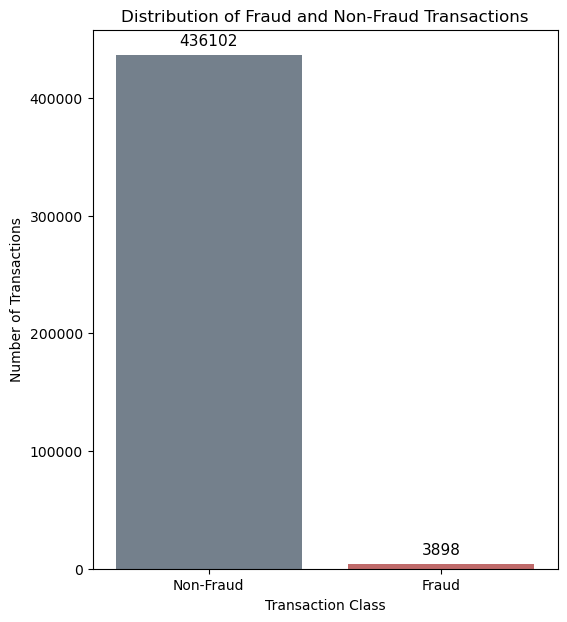

In [132]:
# Lets  Visualize the distribution of fraud and non-fraud transactions
plt.figure(figsize=(6, 7))

ax = sns.countplot(
    x=y_train,
    hue=y_train,
    palette=["slategray", "indianred"],
    legend=False
)


for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=5, fontsize=11)

plt.title("Distribution of Fraud and Non-Fraud Transactions")
plt.xlabel("Transaction Class")
plt.ylabel("Number of Transactions")

plt.xticks([0, 1], ["Non-Fraud", "Fraud"])

plt.show()

#### `1:-` Lets Train The Decision Tree.

In [133]:
# Now we are Initializing the  Decision Tree Classifier
dt_model = DecisionTreeClassifier(
    class_weight="balanced",
    random_state=42
)

In [ ]:
# Now we  Train the Decision Tree model using training data
dt_model.fit(X_train, y_train)

In [ ]:
# now lets try to  predict fraud and non-fraud transactions
y_pred_dt = dt_model.predict(X_test)

In [ ]:
print("Decision Tree Predictions:")
print(y_pred_dt[:20])

Decision Tree Predictions:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


#### `1.1:-` Lets Check The  Prediction Distribution

In [ ]:
# now we will count the predicted fraud and non-fraud transactions

prediction_counts = pd.Series(y_pred_dt).value_counts().sort_index()

print("Decision Tree Prediction Distribution:")
print(prediction_counts)

Decision Tree Prediction Distribution:
0    108762
1      1238
Name: count, dtype: int64


In [ ]:
# Now we will Calculate the percentage  of distributions predictions

prediction_percentage = (
    pd.Series(y_pred_dt)
    .value_counts(normalize=True)
    .sort_index() * 100
)

print("Prediction Percentage:")
print(prediction_percentage.round(2))

Prediction Percentage:
0    98.87
1     1.13
Name: proportion, dtype: float64


#### `1.2:-` Now we will Evaluate The Decision Tree Model

In [ ]:
# Lets Generate a classification report
print("Decision Tree Classification Report:\n")

print(classification_report(
    y_test,
    y_pred_dt,
    target_names=["Non-Fraud", "Fraud"]
))

Decision Tree Classification Report:

              precision    recall  f1-score   support

   Non-Fraud       0.99      0.99      0.99    109025
       Fraud       0.01      0.02      0.02       975

    accuracy                           0.98    110000
   macro avg       0.50      0.50      0.50    110000
weighted avg       0.98      0.98      0.98    110000



#### Observation :-

The Decision Tree Classifier achieved an overall accuracy of 98%. However, its performance in detecting fraud transactions is very poor.

- Fraud Precision: 0.01
- Fraud Recall: 0.02
- Fraud F1-score: 0.02

The model detected only 2% of the actual fraud transactions, indicating that it failed to identify most fraud cases.

#### `1.3:-`Now we will Calculate Confusion matrix

In [ ]:
# Generate confusion matrix
cm_dt = confusion_matrix(y_test, y_pred_dt)

print("Decision Tree Confusion Matrix:")
print(cm_dt)

Decision Tree Confusion Matrix:
[[107804   1221]
 [   958     17]]


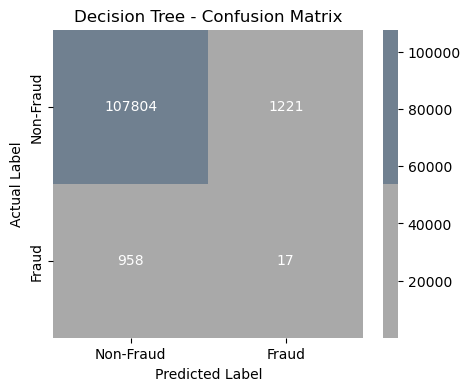

In [ ]:
# Lets Visualize Decision Tree Confusion Matrix

plt.figure(figsize=(5, 4))

sns.heatmap(
    cm_dt,
    annot=True,
    fmt="d",
    cmap=sns.color_palette(["darkgray", "slategray"], as_cmap=True),
    xticklabels=["Non-Fraud", "Fraud"],
    yticklabels=["Non-Fraud", "Fraud"]
)

plt.title("Decision Tree - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()

### Observation

The confusion matrix shows that the Decision Tree Classifier correctly identified 107,804 non-fraud transactions but detected only 17 fraud transactions.

- True Negative: 107,804
- False Positive: 1,221
- False Negative: 958
- True Positive: 17

The model failed to detect most fraud transactions, resulting in a very low fraud detection rate.


#### `2:-` Now we will Train The Random Forest Model

In [ ]:
# lets frist Initialize the Random Forest Classifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

In [ ]:
# Now lets do the same  thing, Train the Random Forest model using training data

rf_model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [ ]:
# Lets Predict fraud and non-fraud transactions

y_pred_rf = rf_model.predict(X_test)

In [ ]:
# now we are agin checkin the first 20 predictions of the Random Forest model
print("Random Forest Predictions:")
print(y_pred_rf[:20])

Random Forest Predictions:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


#### `2.1:-` Lets Check The  Prediction Distribution

In [ ]:
# lets Count the predicted fraud and non-fraud transactions

prediction_counts_rf = pd.Series(y_pred_rf).value_counts().sort_index()

print("Random Forest Prediction Distribution:")
print(prediction_counts_rf)

Random Forest Prediction Distribution:
0    110000
Name: count, dtype: int64


In [ ]:
# Now we will Calculate the percentage  of distributions predictions
prediction_percentage_rf = (
    pd.Series(y_pred_rf)
    .value_counts(normalize=True)
    .sort_index() * 100
)

print("Random Forest Prediction Percentage:")
print(prediction_percentage_rf.round(2))


Random Forest Prediction Percentage:
0    100.0
Name: proportion, dtype: float64


### Observation

The Random Forest Classifier predicted all 110,000 test transactions as non-fraudulent (Class 0).

- Non-Fraud Predictions: 110,000 (100%)
- Fraud Predictions: 0 (0%)

The model failed to identify any fraudulent transactions using its default classification threshold of 0.5.

#### `2.2:-` Now we will Evaluate The Random Forest Model

In [ ]:
# Again we are just Generateing  the classification report for Random Forest
print("Random Forest Classification Report:")
print(classification_report(
    y_test,
    y_pred_rf,
    target_names=["Non-Fraud", "Fraud"]
))

Random Forest Classification Report:
              precision    recall  f1-score   support

   Non-Fraud       0.99      1.00      1.00    109025
       Fraud       0.00      0.00      0.00       975

    accuracy                           0.99    110000
   macro avg       0.50      0.50      0.50    110000
weighted avg       0.98      0.99      0.99    110000



#### Observation
The model correctly classified most non-fraud transactions but failed to identify any fraudu transactions.

- **True Negative (TN):** All correctly identified non-fraud transactions.
- **False Positive (FP):** Non-fraudulent transactions incorrectly classified as fraud.
- **False Negative (FN):** Fraudulent transactions incorrectly classified as non-fraud.
- **True Positive (TP):** Correctly identified fraud transactions.

The confusion matrix indicates that the model classified all 975 fraudtransactions as non-fraud.

#### `2.3:-`Now we will Calculate Confusion matrix

In [ ]:
# now lets Generate the confusion matrix
cm_rf = confusion_matrix(y_test, y_pred_rf)

print("Random Forest Confusion Matrix:")
print(cm_rf)

Random Forest Confusion Matrix:
[[109025      0]
 [   975      0]]


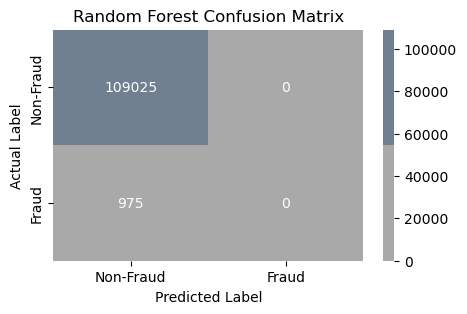

In [ ]:
# no we will Visualize the Random Forest confusion matrix
plt.figure(figsize=(5, 3))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap=sns.color_palette(["darkgray", "slategray"], as_cmap=True),
    xticklabels=["Non-Fraud", "Fraud"],
    yticklabels=["Non-Fraud", "Fraud"]
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()

### Observation

The confusion matrix shows that the Random Forest Classifier correctly identified all 109,025 non-fraud transactions.

However, the model failed to identify any of the 975 fraud transactions.

- **True Negative (TN):** 109,025
- **False Positive (FP):** 0
- **False Negative (FN):** 975
- **True Positive (TP):** 0

The model classified every transaction as non-fraudulent, resulting in zero fraud detection.


#### `3:-`Now lets Train the XGBoost

In [ ]:
# first we will Calculate the number of non-fraud and fraud transactions
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

# now we will Calculate the class imbalance ratio
scale_pos_weight = negative_count / positive_count

print("Non-Fraud Transactions:", negative_count)
print("Fraud Transactions:", positive_count)
print("Scale Pos Weight:", round(scale_pos_weight, 2))

Non-Fraud Transactions: 436102
Fraud Transactions: 3898
Scale Pos Weight: 111.88


In [ ]:
# Now lets initialize the XGBoost Classifier
xgb_model = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    scale_pos_weight=scale_pos_weight,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

In [ ]:
# Train the XGBoost model using training data
xgb_model.fit(X_train, y_train)

,"objective objective: typing.Union[str, xgboost.objective.Objective, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'binary:logistic'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets im

In [ ]:
# now we will Generate predictions using the trained XGBoost model
y_pred_xgb = xgb_model.predict(X_test)

# And we will Display the first 20 predictions
print("XGBoost Predictions:")
print(y_pred_xgb[:20])

XGBoost Predictions:
[0 0 0 0 0 1 0 0 0 0 0 0 0 0 1 0 0 0 0 0]


#### `3.1:-` Lets Check The  Prediction Distribution

In [ ]:
# Count the predicted non-fraud and fraud transactions
prediction_counts_xgb = pd.Series(y_pred_xgb).value_counts().sort_index()

print("XGBoost Prediction Distribution:")
print(prediction_counts_xgb)

XGBoost Prediction Distribution:
0    90981
1    19019
Name: count, dtype: int64


In [ ]:
# Now we will Calculate the percentage of each predicted class
prediction_percentage_xgb = (
    pd.Series(y_pred_xgb)
    .value_counts(normalize=True)
    .sort_index() * 100
)

print("XGBoost Prediction Percentage:")
print(prediction_percentage_xgb.round(2))

XGBoost Prediction Percentage:
0    82.71
1    17.29
Name: proportion, dtype: float64


#### Observation

The XGBoost Classifier predicted 90,981 transactions as non-fraud and 19,019 transactions as fraudulent.

- **Non-Fraud Predictions:** 90,981 (82.71%)
- **Fraud Predictions:** 19,019 (17.29%)

Unlike the Decision Tree and Random Forest models, XGBoost successfully predicted both classes.

However, predicting a transaction as fraud does not necessarily mean it is actually fraud. we need to check if this predections are true or not.

#### `3.2:-` Now we will Evaluate The XGBoost Classification Report

In [ ]:
# No we will generate the classification report for XGBoost
print("XGBoost Classification Report:")
print(classification_report(
    y_test,
    y_pred_xgb,
    target_names=["Non-Fraud", "Fraud"]
))

XGBoost Classification Report:
              precision    recall  f1-score   support

   Non-Fraud       0.99      0.83      0.90    109025
       Fraud       0.01      0.22      0.02       975

    accuracy                           0.82    110000
   macro avg       0.50      0.52      0.46    110000
weighted avg       0.98      0.82      0.89    110000



#### Observation :-

The XGBoost Classifier achieved an overall accuracy of approximately 82%. Unlike the Decision Tree and Random Forest models, it successfully identified some fraud transactions.

The model achieved a fraud precision of 0.01, recall of 0.22, and F1-score of 0.02.

- **Precision (0.01):** Only a small proportion of transactions predicted as fraud were actually fraud.
- **Recall (0.22):** The model detected approximately 22% of the actual fraud transactions.
- **F1-score (0.02):** The model showed poor overall performance in balancing fraud precision and recall.

**Conclusion:** XGBoost performs better than the  Decision Tree and Random Forest models in detecting fraudulent transactions. However, its low fraud precision indicates that it incorrectly flags many non-fraud transactions as fraud. we need to Further optimizw this model.

#### `3.3:-`Now we will Calculate Confusion matrix

In [ ]:
# now we will Generate the confusion matrix for XGBoost
cm_xgb = confusion_matrix(y_test, y_pred_xgb)

print("XGBoost Confusion Matrix:")
print(cm_xgb)

XGBoost Confusion Matrix:
[[90218 18807]
 [  763   212]]


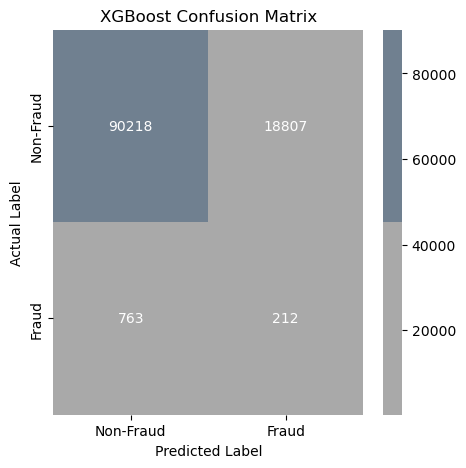

In [ ]:
# Now lets Visualize the XGBoost confusion matrix
plt.figure(figsize=(5, 5))

sns.heatmap(
    cm_xgb,
    annot=True,
    fmt="d",
    cmap=sns.color_palette(["darkgray", "slategray"], as_cmap=True),
    xticklabels=["Non-Fraud", "Fraud"],
    yticklabels=["Non-Fraud", "Fraud"]
)

plt.title("XGBoost Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()

#### Observation:-

The confusion matrix visualization provides a clear understanding of how the XGBoost Classifier performs in identifying fraud and non-fraud transactions.

The model produced the following results:

- **True Negative (TN):** 90,218 – Correctly identified non-fraudulent transactions.
- **False Positive (FP):** 18,807 – Non-fraudulent transactions incorrectly classified as fraud.
- **False Negative (FN):** 763 – Fraud transactions incorrectly classified as non-fraud.
- **True Positive (TP):** 212 – Correctly identified fraud transactions.

The visualization shows that the model successfully detected 212 fraud transactions but missed 763 actual fraud transactions. It also incorrectly flagged 18,807 non-fraudulent transactions as fraudulent.

#### `4:-`Lets Compair All Three Models

In [ ]:
# Now we will Calculate evaluation metrics for all three models

model_results = {
    "Decision Tree": {
        "Accuracy": accuracy_score(y_test, y_pred_dt),
        "Precision": precision_score(y_test, y_pred_dt, zero_division=0),
        "Recall": recall_score(y_test, y_pred_dt, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred_dt, zero_division=0)
    },

    "Random Forest": {
        "Accuracy": accuracy_score(y_test, y_pred_rf),
        "Precision": precision_score(y_test, y_pred_rf, zero_division=0),
        "Recall": recall_score(y_test, y_pred_rf, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred_rf, zero_division=0)
    },

    "XGBoost": {
        "Accuracy": accuracy_score(y_test, y_pred_xgb),
        "Precision": precision_score(y_test, y_pred_xgb, zero_division=0),
        "Recall": recall_score(y_test, y_pred_xgb, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred_xgb, zero_division=0)
    }
}

# Convert the results into a DataFrame
comparison_df = pd.DataFrame(model_results).T

# Display the comparison table
print("Model Performance Comparison:")
display(comparison_df.round(4))

Model Performance Comparison:


,Accuracy,Precision,Recall,F1-Score
Decision Tree,0.9802,0.0137,0.0174,0.0154
Random Forest,0.9911,0.0000,0.0000,0.0000
XGBoost,0.8221,0.0111,0.2174,0.0212


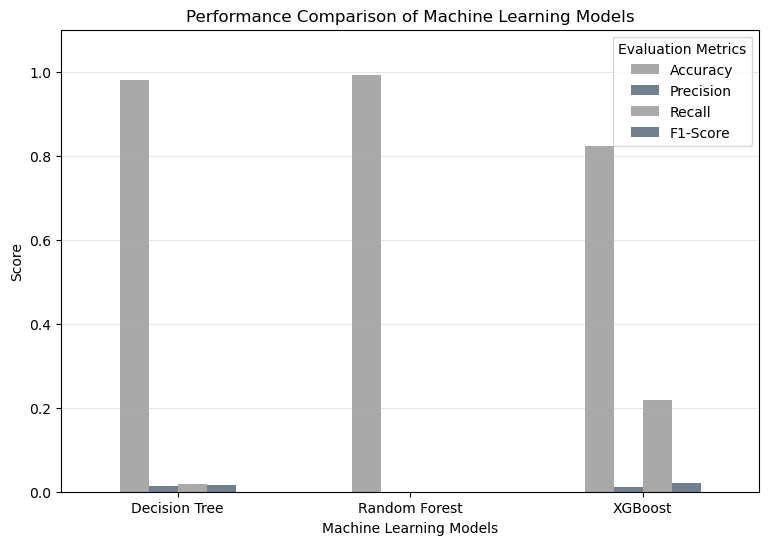

In [ ]:
comparison_df.plot(
    kind="bar",
    figsize=(9, 6),
    color=["darkgray", "slategray", "darkgray", "slategray"]
)

plt.title("Performance Comparison of Machine Learning Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.legend(title="Evaluation Metrics")
plt.ylim(0, 1.1)
plt.grid(axis="y", alpha=0.3)

plt.show()

#### Observation :-

The performance comparison of the three baseline machine learning models reveals significant differences in their fraud detection capabilities.

- **Decision Tree:** Achieved 98.02% accuracy, 1.37% precision, 1.74% recall and 1.54% F1-score.
- **Random Forest:** Achieved 99.11% accuracy but failed to detect any fraudulent transactions.
- **XGBoost:** Achieved 82.21% accuracy, 1.11% precision, 21.74% recall and 2.12% F1-score.

Although Random Forest achieved the highest accuracy, it failed to identify fraudulent transactions. XGBoost achieved the highest fraud recall and F1-score among the three models.

**Conclusion:** Based on fraud detection performance, XGBoost is the strongest candidate for further optimization. its precision is still very low, indicating a high number of false-positive predictions. we need to do Hyperparameter tuning and further evaluation so that we can improve its performance.

#### `Note:-`After comparing the performance of Decision Tree, Random Forest and XGBoost, XGBoost is selected as the candidate for further optimization.

#### `5:-`Hyperparameter Tuning

In [ ]:
# First we import libraries required for hyperparameter tuning
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

# Then import parameter distribution utility
from scipy.stats import randint, uniform

`5.1:-`Now we will Define Hyperparameter Search Space

In [ ]:
# Here in this step we will test different combinations of XGBoost parameters to find a configuration that improves fraud detection performance.

param_distributions = {
    "n_estimators": randint(100, 301),
    "max_depth": randint(3, 9),
    "learning_rate": uniform(0.01, 0.19),
    "min_child_weight": randint(1, 10),
    "subsample": uniform(0.6, 0.4),
    "colsample_bytree": uniform(0.6, 0.4)
}

In [ ]:
# Now we will Configure the Randomized Search CV
# We will use 5-fold Stratified Cross-Validation to evaluate different hyperparameter combinations
cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Initialize Randomized Search with Cross-Validation
random_search = RandomizedSearchCV(
    estimator=XGBClassifier(
        scale_pos_weight=scale_pos_weight,
        eval_metric="logloss",
        random_state=42,
        n_jobs=1
    ),
    param_distributions=param_distributions,
    n_iter=15,
    scoring="average_precision",
    cv=cv_strategy,
    verbose=2,
    random_state=42,
    n_jobs=-1
)


In [ ]:
# Now lets Perform the Hyperparameter Tuning
random_search.fit(X_train, y_train)

Fitting 5 folds for each of 15 candidates, totalling 75 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBClassifier...ree=None, ...)"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'colsample_bytree': <scipy.stats....00201653CA850>, 'learning_rate': <scipy.stats....0020162B01FD0>, 'max_depth': <scipy.stats....00201653CA0D0>, 'min_child_weight': <scipy.stats....00201653CA490>, ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",15
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'average_precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer 

In [ ]:
# now we will just Display the best hyperparameters
print("Best Hyperparameters:")
print(random_search.best_params_)

Best Hyperparameters:
{'colsample_bytree': np.float64(0.908897907718663), 'learning_rate': np.float64(0.04775597949149276), 'max_depth': 5, 'min_child_weight': 3, 'n_estimators': 180, 'subsample': np.float64(0.88453678109946)}


In [ ]:
# Now we will just Display the best Average Precision score
print("Best Cross-Validation Average Precision:")
print(round(random_search.best_score_, 4))

Best Cross-Validation Average Precision:
0.0196


#### Observation :–
After performing hyperparameter tuning using RandomizedSearchCV with 5-fold Stratified Cross-Validation, the following hyperparameter combination was identified as the best configuration:
**Best Hyperparameters:**

- **n_estimators:** 180
- **max_depth:** 5
- **learning_rate:** 0.0478
- **min_child_weight:** 3
- **subsample:** 0.8845
- **colsample_bytree:** 0.9089

**Best Cross-Validation Average Precision:** 0.0196

The selected configuration achieved an Average Precision score of 0.0196 across the validation folds. Although it was the best combination among the 15 configurations tested, the score indicates that the model's fraud detection performance still requires improvement.

#### `6:-`Now we will Create the Tuned XGBoost Model

In [ ]:
# first we will Retrieve the best tuned XGBoost model
best_xgb_model = random_search.best_estimator_

print("Tuned XGBoost Model Created Successfully!")

Tuned XGBoost Model Created Successfully!


In [ ]:
# Now we will Generate predictions using the tuned XGBoost model
y_pred_tuned = best_xgb_model.predict(X_test)

# And we display the first 30 predictions
print("Tuned XGBoost Predictions:")
print(y_pred_tuned[:30])

Tuned XGBoost Predictions:
[0 0 0 0 0 0 0 0 1 0 0 1 0 0 0 0 0 0 0 0 1 0 0 1 0 0 0 0 0 0]


#### `7:-`Now we will see the XGBoost Prediction Distribution

In [ ]:
# Now we will Count the predicted non-fraud and fraud transactions
prediction_counts_tuned = (
    pd.Series(y_pred_tuned)
    .value_counts()
    .sort_index()
)

print("Tuned XGBoost Prediction Distribution:")
print(prediction_counts_tuned)

Tuned XGBoost Prediction Distribution:
0    91973
1    18027
Name: count, dtype: int64


#### `8:-`Now Calculate prediction percentages

In [ ]:
# Calculate prediction percentages for the tuned model
prediction_percentage_tuned = (
    pd.Series(y_pred_tuned)
    .value_counts(normalize=True)
    .sort_index() * 100
)

print("Tuned XGBoost Prediction Percentage:")
print(prediction_percentage_tuned.round(2))

Tuned XGBoost Prediction Percentage:
0    83.61
1    16.39
Name: proportion, dtype: float64


### Observation :–

The tuned XGBoost Classifier predicted 91,973 transactions as non-fraud(83.61%) and 18,027 transactions as fraud (16.39%).

Compared with the baseline XGBoost model, the tuned model shows a decrease in the percentage of transactions classified as fraud from 17.29% to 16.39%.


#### `9:-`Now we will Generate the Tuned classification Report

In [ ]:

print("Tuned XGBoost Classification Report:")
print(classification_report(
    y_test,
    y_pred_tuned,
    target_names=["Non-Fraud", "Fraud"]
))

Tuned XGBoost Classification Report:
              precision    recall  f1-score   support

   Non-Fraud       0.99      0.84      0.91    109025
       Fraud       0.01      0.24      0.02       975

    accuracy                           0.83    110000
   macro avg       0.50      0.54      0.47    110000
weighted avg       0.98      0.83      0.90    110000



### Observation :-

The tuned XGBoost Classifier achieved an overall accuracy of approximately 83%. It recorded a fraud precision of 0.01, recall of 0.24 and F1-score of 0.02.

Compared with the baseline XGBoost model:

- **Accuracy:** Improved from 82.21% to approximately 83%.
- **Precision:** Remained approximately 1%.
- **Recall:** Improved from 21.74% to approximately 24%.
- **F1-score:** Remained approximately 2%.

The improvement in fraud recall indicates that the tuned model can identify a larger proportion of actual fraud transactions compared with the baseline model.

However, its low fraud precision indicates that many non-fraud transactions are still incorrectly classified as fraud.

**Conclusion:** Hyperparameter tuning has produced a slight improvement in the fraud detection capability of XGBoost, particularly in recall. However we need to do  further optimization in the precision and overall fraud detection performance.

In [ ]:
# lets once also Generate the confusion matrix for tuned XGBoost
cm_tuned = confusion_matrix(y_test, y_pred_tuned)

print("Tuned XGBoost Confusion Matrix:")
print(cm_tuned)

Tuned XGBoost Confusion Matrix:
[[91234 17791]
 [  739   236]]


#### `10`:- Now we will do the Advance Hyperparameter Tunning

In [ ]:
# agin just defining the  advanced hyperparameter search space
advanced_param_distributions = {
    "n_estimators": randint(150, 501),
    "max_depth": randint(3, 10),
    "learning_rate": uniform(0.01, 0.19),
    "min_child_weight": randint(1, 15),
    "subsample": uniform(0.6, 0.4),
    "colsample_bytree": uniform(0.6, 0.4),
    "gamma": uniform(0, 5),
    "reg_alpha": uniform(0, 5),
    "reg_lambda": uniform(0.5, 5)
}

In [ ]:
# Now we will initialize the advanced RandomizedSearchCV
advanced_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Initialize advanced Randomized Search
advanced_search = RandomizedSearchCV(
    estimator=XGBClassifier(
        scale_pos_weight=scale_pos_weight,
        eval_metric="logloss",
        random_state=42,
        n_jobs=1
    ),
    param_distributions=advanced_param_distributions,
    n_iter=30,
    scoring="average_precision",
    cv=advanced_cv,
    verbose=2,
    random_state=42,
    n_jobs=-1
)

In [ ]:
advanced_search.fit(X_train, y_train)

Fitting 5 folds for each of 30 candidates, totalling 150 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBClassifier...ree=None, ...)"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'colsample_bytree': <scipy.stats....0020168D00950>, 'gamma': <scipy.stats....00201599728B0>, 'learning_rate': <scipy.stats....0020159E44770>, 'max_depth': <scipy.stats....0020159E44640>, ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",30
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'average_precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User 

In [ ]:
 # Now lets  see whats the best hyperparameters from advanced tuning
print("Best Advanced Hyperparameters:")
print(advanced_search.best_params_)

Best Advanced Hyperparameters:
{'colsample_bytree': np.float64(0.6307919639315172), 'gamma': np.float64(1.4487572645688402), 'learning_rate': np.float64(0.04063204457826084), 'max_depth': 4, 'min_child_weight': 10, 'n_estimators': 194, 'reg_alpha': np.float64(1.47816842918857), 'reg_lambda': np.float64(1.027471299151353), 'subsample': np.float64(0.782613828193164)}


In [ ]:
# also lets see  the best Average Precision score
print("Best Advanced Cross-Validation Average Precision:")
print(round(advanced_search.best_score_, 4))

Best Advanced Cross-Validation Average Precision:
0.0199


#### `11:-`Second XGBOOSt Model

In [ ]:
# NOw we will Retrieve the best model from advanced hyperparameter tuning
advanced_xgb_model = advanced_search.best_estimator_

print("Advanced Tuned XGBoost Model Created Successfully!")

Advanced Tuned XGBoost Model Created Successfully!


In [ ]:
# lets  Generate predictions using the advanced tuned XGBoost model
y_pred_advanced = advanced_xgb_model.predict(X_test)

# Display the first 20 predictions
print("Advanced Tuned XGBoost Predictions:")
print(y_pred_advanced[:20])

Advanced Tuned XGBoost Predictions:
[0 0 0 0 0 0 1 0 1 0 0 0 0 0 1 0 0 0 0 0]


#### `12:-`Advanced Tuned XGBoost Prediction Distribution

In [ ]:
# now we will  Count predicted non-fraud and fraud transactions
prediction_counts_advanced = (
    pd.Series(y_pred_advanced)
    .value_counts()
    .sort_index()
)

print("Advanced Tuned XGBoost Prediction Distribution:")
print(prediction_counts_advanced)

Advanced Tuned XGBoost Prediction Distribution:
0    91808
1    18192
Name: count, dtype: int64


#### Observation :– 

The Advanced Tuned XGBoost Classifier predicted 91,808 transactions as non-fraudulent and 18,192 transactions as fraudulent.

- **Non-Fraud Predictions:** 91,808
- **Fraud Predictions:** 18,192

Compared with the first tuned XGBoost model, the advanced tuned model predicted 165 more transactions as fraud.

**Conclusion:** The advanced tuning process has slightly changed the prediction distribution. However, the distribution alone cannot determine whether the model has improved.

#### `13:-`Now we will again Calculate prediction percentages

In [ ]:
# now lets calculate prediction percentages for advanced tuned XGBoost
prediction_percentage_advanced = (
    pd.Series(y_pred_advanced)
    .value_counts(normalize=True)
    .sort_index() * 100
)

print("Advanced Tuned XGBoost Prediction Percentage:")
print(prediction_percentage_advanced.round(2))

Advanced Tuned XGBoost Prediction Percentage:
0    83.46
1    16.54
Name: proportion, dtype: float64


#### Now let's evaluate the model using Precision, Recall, F1-score and Accuracy.

In [ ]:
print("Advanced Tuned XGBoost Classification Report:")
print(classification_report(
    y_test,
    y_pred_advanced,
    target_names=["Non-Fraud", "Fraud"]
))

Advanced Tuned XGBoost Classification Report:
              precision    recall  f1-score   support

   Non-Fraud       0.99      0.84      0.91    109025
       Fraud       0.01      0.25      0.03       975

    accuracy                           0.83    110000
   macro avg       0.50      0.54      0.47    110000
weighted avg       0.98      0.83      0.90    110000



### Observation :– 

The Advanced Tuned XGBoost Classifier achieved an overall accuracy of approximately 83%, with a fraud precision of 0.01, recall of 0.25 and F1-score of 0.03.

Compared with the previous XGBoost models:

- **Accuracy:** Remained approximately 83%.
- **Precision:** Remained approximately 1%.
- **Recall:** Improved from 21.74% in the baseline model and approximately 24% in the first tuned model to 25%.
- **F1-score:** Improved to approximately 3%.

The improvement in fraud recall indicates that the advanced tuned model can identify a larger proportion of actual fraud transactions.

However, its low precision indicates that many non-fraud transactions are still incorrectly classified as fraud.

**Conclusion:** The second round of hyperparameter tuning improved the fraud detection recall of XGBoost. The advanced tuned model currently shows the best fraud detection performance among the three XGBoost versions  but still its further need evaluation.

### `Observation – XGBoost Hyperparameter Tuning and Model Selection`

After performing two rounds of hyperparameter tuning using RandomizedSearchCV, the XGBoost model showed only a slight improvement in its performance.

The Average Precision score increased from 0.0196 in the first tuning round to 0.0199 in the second tuning round. Although fraud recall improved to approximately 25%, fraud precision remained very low at approximately 1%.

These results indicate that repeated hyperparameter tuning has not produced a significant improvement in the overall fraud detection performance of XGBoost.

**Conclusion:** Instead of continuing to tune XGBoost, we will experiment with a different machine learning algorithm called LightGBM (Light Gradient Boosting Machine). We will evaluate its performance and compare it with the previously trained models to determine whether it provides better fraud detection results.

#### `14:-`Now we will try LightGBM Model 

In [ ]:
# Import LightGBM Classifier
from lightgbm import LGBMClassifier

In [ ]:
# LightGBM Classifier
lgbm_model = LGBMClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=-1,
    num_leaves=31,
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

In [ ]:
# now we will train LightGBM model using training data
lgbm_model.fit(X_train, y_train)

,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.1
,n_estimators,100
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,20


In [ ]:
# lets try to predict using the trained LightGBM model
y_pred_lgbm = lgbm_model.predict(X_test)

# Display the first 20 predictions
print("LightGBM Predictions:")
print(y_pred_lgbm[:20])

LightGBM Predictions:
[0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


#### `15:-`Lets do the Prediction Distribution

In [ ]:
# lets Count predicted non-fraud and fraud transactions
prediction_counts_lgbm = (
    pd.Series(y_pred_lgbm)
    .value_counts()
    .sort_index()
)

print("LightGBM Prediction Distribution:")
print(prediction_counts_lgbm)

LightGBM Prediction Distribution:
0    82996
1    27004
Name: count, dtype: int64


#### `16`:-Lets Calculate prediction percentages

In [ ]:
prediction_percentage_lgbm = (
    pd.Series(y_pred_lgbm)
    .value_counts(normalize=True)
    .sort_index() * 100
)

print("LightGBM Prediction Percentage:")
print(prediction_percentage_lgbm.round(2))

LightGBM Prediction Percentage:
0    75.45
1    24.55
Name: proportion, dtype: float64


#### `17:-`Classification Report

In [ ]:
# Generate classification report for LightGBM
print("LightGBM Classification Report:")
print(classification_report(
    y_test,
    y_pred_lgbm,
    target_names=["Non-Fraud", "Fraud"]
))

LightGBM Classification Report:
              precision    recall  f1-score   support

   Non-Fraud       0.99      0.76      0.86    109025
       Fraud       0.01      0.33      0.02       975

    accuracy                           0.75    110000
   macro avg       0.50      0.54      0.44    110000
weighted avg       0.98      0.75      0.85    110000



### Observation :– 

The LightGBM Classifier achieved an overall accuracy of approximately 75%. It recorded a fraud precision of 0.01, recall of 0.33 and F1-score of 0.02.

- **Precision (0.01):** Only a small proportion of transactions predicted as fraud were actually fraud.
- **Recall (0.33):** The model successfully detected approximately 33% of actual fraud transactions.
- **F1-score (0.02):** The model showed a low balance between fraud precision and recall.

Compared with the previously trained models, LightGBM achieved the highest fraud recall so far.

**Conclusion:** LightGBM shows better fraud detection capability in terms of recall compared with the previous baseline and tuned models. However, its low precision indicates that it incorrectly flags many non-fraud transactions as fraud. so ts also need Further evaluation and optimization.

In [ ]:
# lets also Generate the confusion matrix for LightGBM
cm_lgbm = confusion_matrix(y_test, y_pred_lgbm)

print("LightGBM Confusion Matrix:")
print(cm_lgbm)

LightGBM Confusion Matrix:
[[82340 26685]
 [  656   319]]


#### `18:-`Now we will tune the lightGRM

In [ ]:
# lets first Define LightGBM hyperparameter search space

lgbm_param_distributions = {
    "n_estimators": randint(100, 501),
    "learning_rate": uniform(0.01, 0.19),
    "num_leaves": randint(15, 101),
    "max_depth": randint(3, 13),
    "min_child_samples": randint(10, 101),
    "subsample": uniform(0.6, 0.4),
    "colsample_bytree": uniform(0.6, 0.4),
    "reg_alpha": uniform(0, 5),
    "reg_lambda": uniform(0.5, 5)
}

In [ ]:
# Configure Stratified Cross-Validation

lgbm_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# also lets Initialize RandomizedSearchCV

lgbm_search = RandomizedSearchCV(
    estimator=LGBMClassifier(
        scale_pos_weight=scale_pos_weight,
        subsample_freq=1,
        random_state=42,
        n_jobs=1,
        verbosity=-1
    ),
    param_distributions=lgbm_param_distributions,
    n_iter=25,
    scoring="average_precision",
    cv=lgbm_cv,
    verbose=2,
    random_state=42,
    n_jobs=-1
)

In [ ]:
# Perform LightGBM hyperparameter tuning

lgbm_search.fit(X_train, y_train)

Fitting 5 folds for each of 25 candidates, totalling 125 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",LGBMClassifie... verbosity=-1)
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'colsample_bytree': <scipy.stats....002016BE38050>, 'learning_rate': <scipy.stats....0020176F99C50>, 'max_depth': <scipy.stats....002016BDFD750>, 'min_child_samples': <scipy.stats....002016BDFDA50>, ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",25
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'average_precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :

In [ ]:
# lets Display the best hyperparameters

print("Best LightGBM Parameters:")
print(lgbm_search.best_params_)

print("\nBest Cross-Validation Average Precision:")
print(lgbm_search.best_score_)

Best LightGBM Parameters:
{'colsample_bytree': np.float64(0.6831766651472755), 'learning_rate': np.float64(0.11786306228579838), 'max_depth': 4, 'min_child_samples': 99, 'n_estimators': 143, 'num_leaves': 48, 'reg_alpha': np.float64(1.9757511800090721), 'reg_lambda': np.float64(5.1332943289689705), 'subsample': np.float64(0.8909087983425683)}

Best Cross-Validation Average Precision:
0.019946479321421497


In [ ]:
best_lgbm_model = lgbm_search.best_estimator_

print("Best LightGBM model is ready!")

Best LightGBM model is ready!


In [ ]:
# Now lets Predict fraud labels using the best LightGBM model

y_pred_lgbm_tuned = best_lgbm_model.predict(X_test)

In [ ]:
# Check prediction distribution

print("Tuned LightGBM Prediction Distribution:")
print(pd.Series(y_pred_lgbm_tuned).value_counts())

print("\nPrediction Percentage:")
print(
    pd.Series(y_pred_lgbm_tuned)
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)


Tuned LightGBM Prediction Distribution:
0    85784
1    24216
Name: count, dtype: int64

Prediction Percentage:
0    77.99
1    22.01
Name: proportion, dtype: float64


In [ ]:
# Evaluate of the tuned LightGBM model

print("Tuned LightGBM Classification Report:\n")

print(
    classification_report(
        y_test,
        y_pred_lgbm_tuned,
        target_names=["Non-Fraud", "Fraud"]
    )
)

Tuned LightGBM Classification Report:

              precision    recall  f1-score   support

   Non-Fraud       0.99      0.78      0.87    109025
       Fraud       0.01      0.29      0.02       975

    accuracy                           0.78    110000
   macro avg       0.50      0.53      0.45    110000
weighted avg       0.98      0.78      0.87    110000



#### **Observation:- Tuned LightGBM Model**

After performing hyperparameter tuning using RandomizedSearchCV with 5-fold Stratified Cross-Validation, the tuned LightGBM model achieved an Average Precision score of approximately 0.01995.

The model achieved approximately 78% accuracy and 29% fraud recall on the test dataset. Although accuracy improved compared with the baseline LightGBM model, fraud recall decreased from approximately 32.72% to 29%.

Fraud precision also remained very low, indicating that a large number of transactions predicted as fraud were actually non-fraudulent.

Therefore, hyperparameter tuning did not produce a significant improvement in fraud detection performance.